# Collected-data recommendation models and temporal profile analysis

Research question: which measured profile representation best retrieves a returning player in the next season? This is an identity/profile-persistence proxy, not a test of transfer success, forecast production or club-fit relevance. Future candidate profiles are used solely for evaluation; they are unavailable at real scouting time.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR','/tmp/tfm-matplotlib')
os.environ.setdefault('XDG_CACHE_HOME','/tmp/tfm-cache')
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image
from src.data.provenance import sha256
from src.models.collected import EXPERIMENTS, cohorts, evaluate_pair
from src.models.recommend import PlayerRecommender
from scripts.collected_models import verified_inputs
manifest, identity, tables = verified_inputs()
result = json.loads((ROOT/'reports/collected_model_results.json').read_text())
for name, info in result['experiments'].items():
    assert sha256(ROOT/info['model_path']) == info['model_sha256']
    for path, digest in info['output_files'].items(): assert sha256(ROOT/path) == digest
display(Markdown('**Real collected FBref observations only.** Dataset version: `'+result['dataset_version']+'`. Matching method accepted; individual cross-source links remain unverified and are not learned features.'))


**Real collected FBref observations only.** Dataset version: `28dc55e8885f1db9cef608567ca2626231f3bab94d1bb3ad13d73b7273dfa87a`. Matching method accepted; individual cross-source links remain unverified and are not learned features.

## Data and chronological experiment design

Offensive development: 2020/21–2022/23; validation 2023/24; holdout 2024/25. Full-core development: 2020/21–2021/22; validation 2022/23; holdout 2023/24. Different holdout seasons prevent a direct comparison of the two main tracks. Partial 2025/26 and the sparse 2024/25 core snapshot are excluded. Aggregation precedes the 450-minute floor. Goalkeepers are excluded. Repeated player-seasons in development deliberately contribute observed exposure-year profiles; each evaluation season has one row per identity.

In [2]:
for name,spec in EXPERIMENTS.items():
    parts = cohorts(tables[spec['table']],spec['split'])
    display(Markdown('### '+name))
    display(pd.DataFrame([{'split':k,'rows':len(v),'people':v.entity_id.nunique(),'seasons':', '.join(sorted(v.season.unique()))} for k,v in parts.items()]))
    display(parts['train'][spec['features']].isna().sum().rename('training_missing').to_frame())


### offensive

,split,rows,people,seasons
0,train,1183,644,"2020-2021, 2021-2022, 2022-2023"
1,validation,393,393,2023-2024
2,holdout,399,399,2024-2025


,training_missing
gls_p90,0
ast_p90,0
sh_p90,0
sot_p90,0
xg_p90,2
xag_p90,2


### core

,split,rows,people,seasons
0,train,795,525,"2020-2021, 2021-2022"
1,validation,388,388,2022-2023
2,holdout,393,393,2023-2024


,training_missing
gls_p90,0
ast_p90,0
sh_p90,0
sot_p90,0
crs_p90,0
int_p90,0
tklw_p90,0
fls_p90,0
fld_p90,0


### attack_on_core

,split,rows,people,seasons
0,train,795,525,"2020-2021, 2021-2022"
1,validation,388,388,2022-2023
2,holdout,393,393,2023-2024


,training_missing
gls_p90,0
ast_p90,0
sh_p90,0
sot_p90,0
xg_p90,0
xag_p90,0


## Training transformations and model selection

Medians, standardization, PCA and K-means are fitted only on development observations. G+A is omitted because it is algebraically redundant. xAG remains its own feature, never xA. K is selected by training silhouette across 2–8 clusters, with a fixed seed. Profile method selection uses validation MRR only. The original training transformations remain frozen for holdout, including validation-season queries. Scores compare cosine/Euclidean distances, two/four PCA components, a hard cluster gate, goals-only, goals-and-assists and a seeded random baseline. Uniform tie handling gives tied targets expected reciprocal rank/hit probability, avoiding row-order bias.

In [3]:
for name, info in result['experiments'].items():
    display(Markdown(f"**{name}:** validation-selected `{info['selected_method']}`; k={info['selected_k']}; features: "+', '.join(info['feature_cols'])))
    rec = PlayerRecommender.load(ROOT/info['model_path'])
    assert rec.neighbor_method == info['selected_method']
    spec = EXPERIMENTS[name]; parts = cohorts(tables[spec['table']], spec['split'])
    past = parts['train'][parts['train'].season == parts['train'].season.max()]
    before = rec.artifacts.scaler.mean_.copy()
    replay, _ = evaluate_pair(rec,past,parts['validation'],'validation')
    recorded = pd.read_csv(ROOT/f'reports/experiments/collected_{name}_retrieval.csv').query("phase == 'validation'")
    np.testing.assert_allclose(replay.set_index('method').mrr, recorded.set_index('method').mrr)
    np.testing.assert_equal(before, rec.artifacts.scaler.mean_)
print('All validation experiments replayed with frozen model transformations.')


**offensive:** validation-selected `euclidean_profile`; k=2; features: gls_p90, ast_p90, sh_p90, sot_p90, xg_p90, xag_p90

**core:** validation-selected `euclidean_profile`; k=2; features: gls_p90, ast_p90, sh_p90, sot_p90, crs_p90, int_p90, tklw_p90, fls_p90, fld_p90

**attack_on_core:** validation-selected `euclidean_profile`; k=2; features: gls_p90, ast_p90, sh_p90, sot_p90, xg_p90, xag_p90

All validation experiments replayed with frozen model transformations.


## Baselines and uncertainty

MRR, Recall@5/10 and NDCG@10 use one same-person target per returning-player query. Players absent from the next eligible cohort are reported by the returning-player fraction rather than assigned invented future profiles. The confidence intervals use 200 paired player-query bootstrap replicates and are conditional on these archive cohorts; they do not remove survival/selection bias.

### offensive

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,target_available_fraction,selected_on_validation
0,validation,cluster_cosine,249,393,0.062297,0.047349,0.083121,0.088353,0.915663,False
1,validation,cosine_profile,249,393,0.061137,0.046493,0.081683,0.076305,1.000000,False
2,validation,euclidean_profile,249,393,0.065250,0.049352,0.086667,0.080321,1.000000,True
3,validation,goals_assists,249,393,0.039363,0.029536,0.052754,0.046768,1.000000,False
4,validation,goals_only,249,393,0.024841,0.021849,0.029139,0.014628,1.000000,False
5,validation,pca2_cosine,249,393,0.040091,0.028233,0.053375,0.040161,1.000000,False
6,validation,pca2_euclidean,249,393,0.043130,0.035177,0.053050,0.052209,1.000000,False
7,validation,pca4_cosine,249,393,0.056002,0.041708,0.072977,0.052209,1.000000,False
8,validation,pca4_euclidean,249,393,0.061588,0.046023,0.079445,0.080321,1.000000,False
9,validation,random,249,393,0.019657,0.012499,0.029576,0.012048,1.000000,False


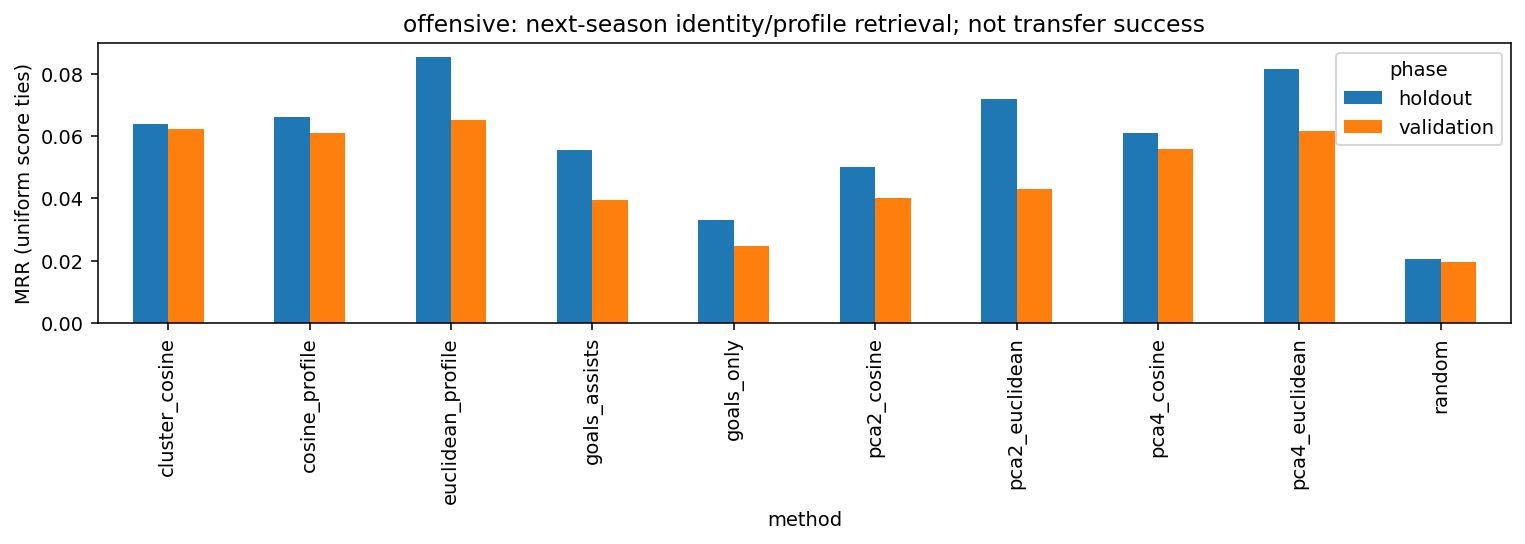

### core

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,target_available_fraction,selected_on_validation
0,validation,cluster_cosine,248,388,0.196910,0.156091,0.234158,0.270161,0.911290,False
1,validation,cosine_profile,248,388,0.200570,0.159329,0.238283,0.274194,1.000000,False
2,validation,euclidean_profile,248,388,0.227642,0.183754,0.265669,0.310484,1.000000,True
3,validation,goals_assists,248,388,0.035116,0.025322,0.048120,0.041818,1.000000,False
4,validation,goals_only,248,388,0.035855,0.023696,0.050169,0.038978,1.000000,False
5,validation,pca2_cosine,248,388,0.054564,0.044607,0.069592,0.064516,1.000000,False
6,validation,pca2_euclidean,248,388,0.102825,0.081220,0.128653,0.137097,1.000000,False
7,validation,pca4_cosine,248,388,0.138072,0.109831,0.172795,0.193548,1.000000,False
8,validation,pca4_euclidean,248,388,0.171421,0.140828,0.208954,0.241935,1.000000,False
9,validation,random,248,388,0.016833,0.011182,0.023053,0.016129,1.000000,False


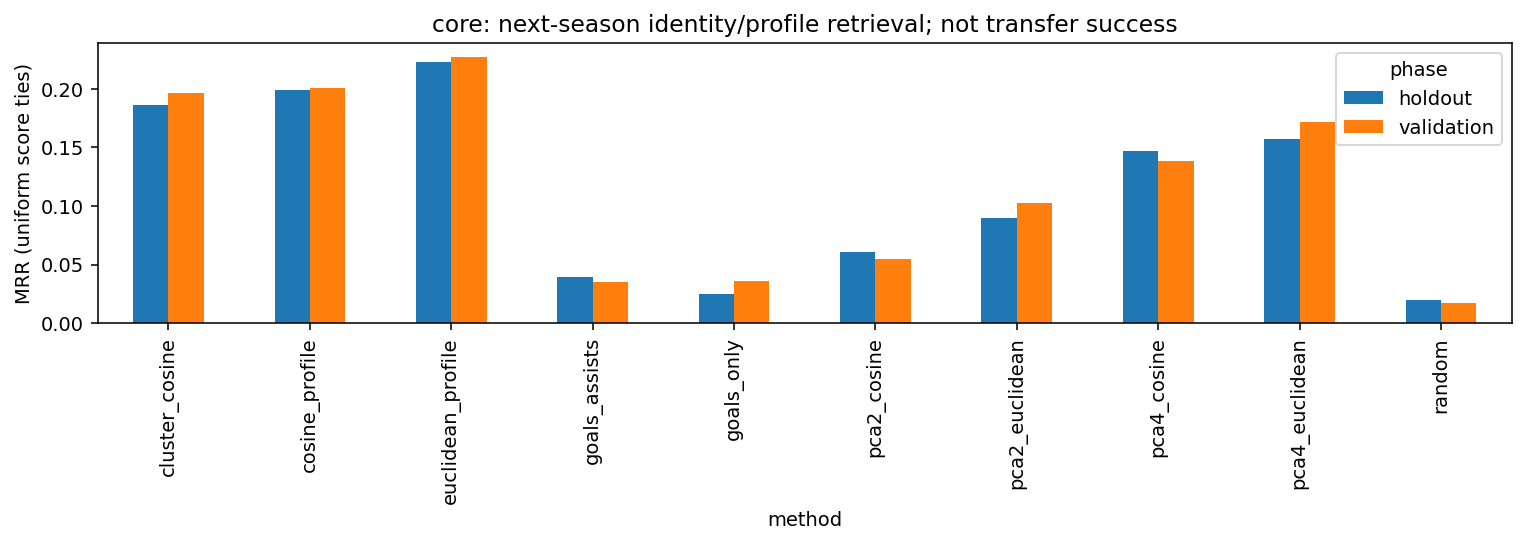

### attack_on_core

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,target_available_fraction,selected_on_validation
0,validation,cluster_cosine,248,388,0.061314,0.046836,0.079837,0.076613,0.866935,False
1,validation,cosine_profile,248,388,0.059544,0.046096,0.077738,0.072581,1.000000,False
2,validation,euclidean_profile,248,388,0.078611,0.055803,0.101289,0.104839,1.000000,True
3,validation,goals_assists,248,388,0.035116,0.025322,0.048120,0.041818,1.000000,False
4,validation,goals_only,248,388,0.035855,0.023696,0.050169,0.038978,1.000000,False
5,validation,pca2_cosine,248,388,0.034808,0.027321,0.044318,0.028226,1.000000,False
6,validation,pca2_euclidean,248,388,0.053693,0.043030,0.064370,0.080645,1.000000,False
7,validation,pca4_cosine,248,388,0.053832,0.041025,0.070344,0.048387,1.000000,False
8,validation,pca4_euclidean,248,388,0.066623,0.048976,0.084151,0.092742,1.000000,False
9,validation,random,248,388,0.016833,0.011182,0.023053,0.016129,1.000000,False


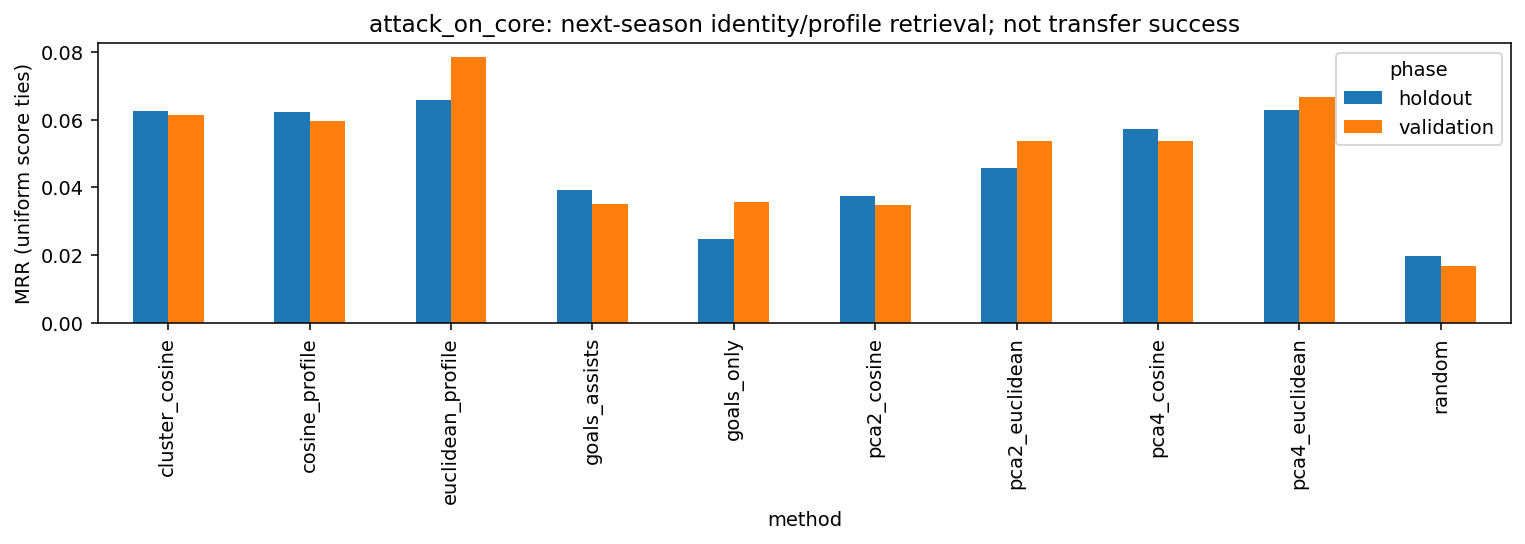

In [4]:
for name in result['experiments']:
    scores=pd.read_csv(ROOT/f'reports/experiments/collected_{name}_retrieval.csv')
    display(Markdown('### '+name));display(scores[['phase','method','queries','candidate_count','mrr','mrr_ci_low','mrr_ci_high','recall_at_5','target_available_fraction','selected_on_validation']])
    display(Image(filename=str(ROOT/f'reports/experiments/collected_{name}_retrieval.png')))


## PCA interpretation

The offensive PC1 loads strongly on goals, shots, shots on target and xG, while PC2 emphasizes assists/xAG. The core PC1 contrasts attacking rates with interceptions/tackles; PC2 mixes crossing, tackling, fouls and fouls drawn. These covariance axes are descriptive. Their signs are arbitrary and they are not labelled tactical roles. High explained variance alone does not justify using fewer dimensions for nearest-player recommendations.

**offensive:** first two components explain 87.9%; first four explain 96.7%.

,Unnamed: 0,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,PC1,0.435647,0.268886,0.458529,0.467641,0.455462,0.318637
1,PC2,-0.254173,0.678729,-0.141184,-0.181379,-0.248926,0.599940
2,PC3,0.634103,0.333742,-0.569412,-0.256772,0.199646,-0.237717
3,PC4,0.266385,-0.596240,-0.260690,-0.154705,0.033534,0.693195


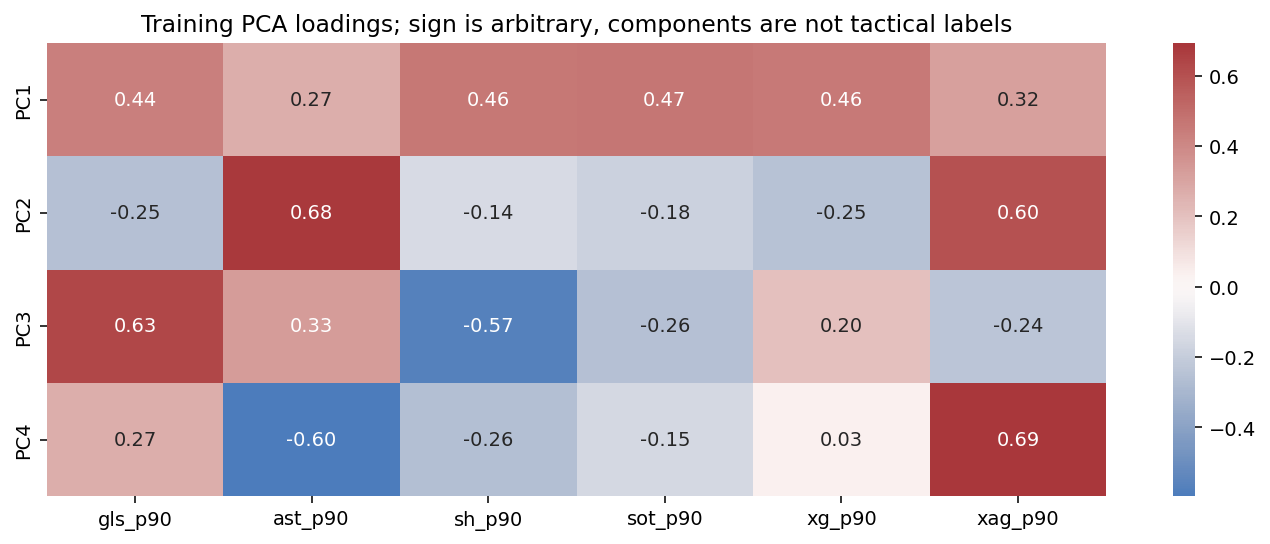

**core:** first two components explain 58.1%; first four explain 79.8%.

,Unnamed: 0,gls_p90,ast_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
0,PC1,0.433905,0.258465,0.473183,0.477798,0.094068,-0.395109,-0.246736,0.018569,0.257966
1,PC2,-0.165086,0.267846,0.025732,-0.060538,0.443844,0.059820,0.519383,0.455310,0.468014
2,PC3,0.098648,-0.477655,0.096170,0.093580,-0.580632,-0.015458,0.083553,0.603845,0.187422
3,PC4,0.386285,0.217610,0.157905,0.275039,-0.202096,0.451275,0.568702,-0.111583,-0.349977


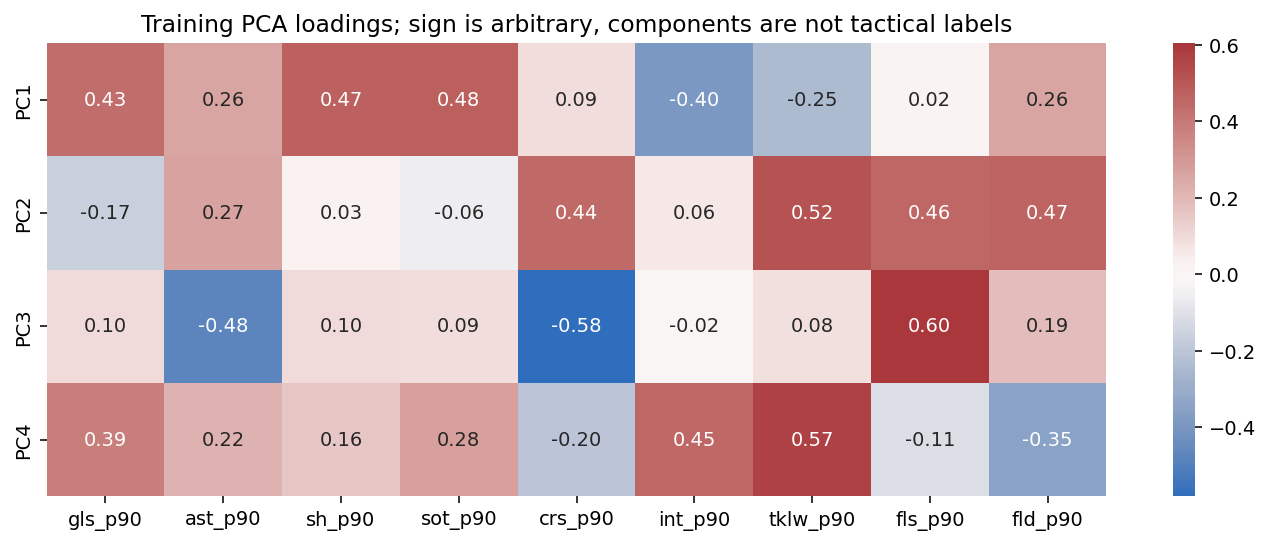

**attack_on_core:** first two components explain 87.7%; first four explain 96.4%.

,Unnamed: 0,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,PC1,0.435035,0.281097,0.455173,0.464363,0.454651,0.319696
1,PC2,-0.254386,0.668544,-0.147315,-0.203587,-0.240652,0.606032
2,PC3,0.646052,0.285041,-0.608150,-0.237539,0.193500,-0.194048
3,PC4,0.226374,-0.626592,-0.217615,-0.129143,0.027673,0.700954


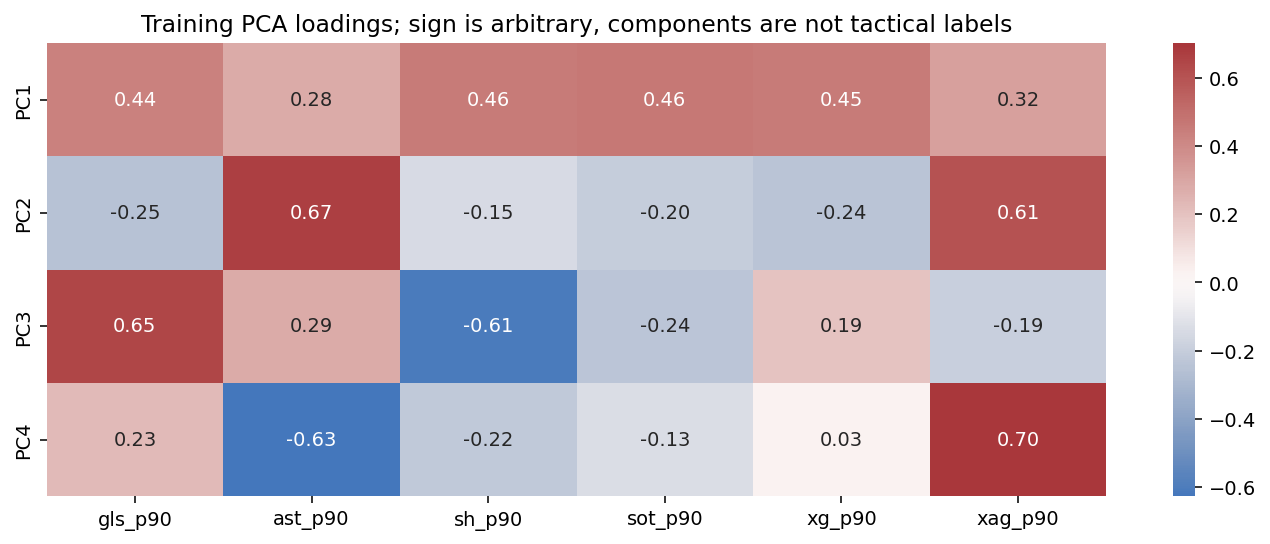

Both main tracks selected full standardized Euclidean profiles on validation. PCA alternatives reduced holdout retrieval MRR. Compression is retained for analysis, rather than imposed on recommendation distances.

In [5]:
for name,info in result['experiments'].items():
    display(Markdown(f"**{name}:** first two components explain {sum(info['pca_explained_variance'][:2]):.1%}; first four explain {sum(info['pca_explained_variance']):.1%}."))
    display(pd.read_csv(ROOT/f'reports/experiments/collected_{name}_pca_loadings.csv'))
    display(Image(filename=str(ROOT/f'reports/experiments/collected_{name}_pca_loadings.png')))
display(Markdown('Both main tracks selected full standardized Euclidean profiles on validation. PCA alternatives reduced holdout retrieval MRR. Compression is retained for analysis, rather than imposed on recommendation distances.'))


## K-means interpretation and robustness

Two clusters are selected in the main tracks. They mainly separate stronger attacking output from the remaining profiles; position composition supports that description. They do not establish six tactical roles. Low season association in development does not prove absence of future drift. Seed agreement describes optimization stability, not scouting validity. The hard cluster gate loses correct same-player targets when their next-season cluster changes, so it is not selected as a shortlist filter.

### offensive

,k,training_silhouette,min_cluster_size,selection_scope
0,2,0.483297,339,training_only
1,3,0.385314,201,training_only
2,4,0.402009,75,training_only
3,5,0.333137,64,training_only
4,6,0.329077,43,training_only
5,7,0.308149,38,training_only
6,8,0.320980,24,training_only


,cluster,DF,FW,MF
0,0,7,247,85
1,1,461,41,342


,position_nmi,season_nmi,seed_ari_mean
0,0.343962,0.000735,1.0


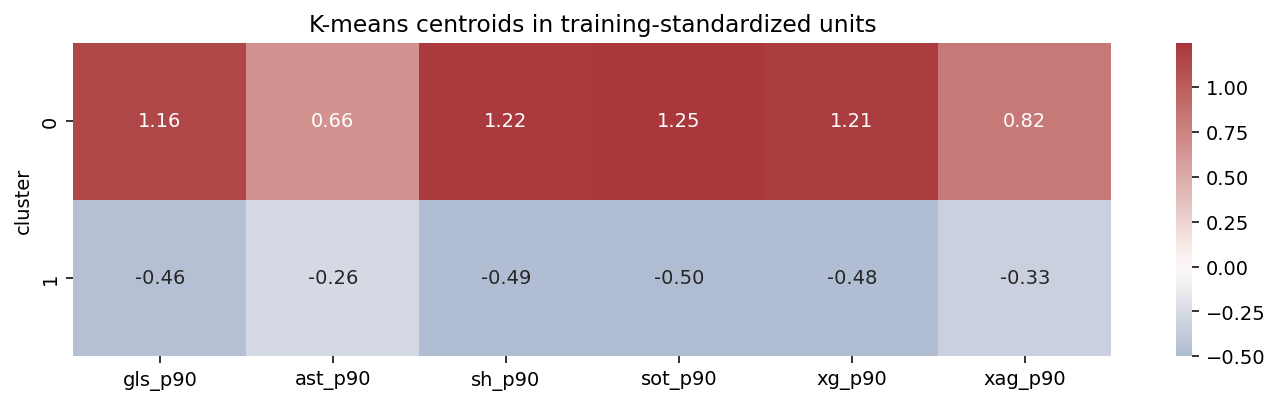

,,mean,min,max
position,method,,,
DF,euclidean_profile,1.000000,1.000000,1.0
FW,euclidean_profile,0.983333,0.666667,1.0
MF,euclidean_profile,1.000000,1.000000,1.0


### core

,k,training_silhouette,min_cluster_size,selection_scope
0,2,0.307923,281,training_only
1,3,0.235510,160,training_only
2,4,0.200132,129,training_only
3,5,0.199618,84,training_only
4,6,0.161767,91,training_only
5,7,0.151086,65,training_only
6,8,0.138270,56,training_only


,cluster,DF,FW,MF
0,0,4,181,96
1,1,307,10,197


,position_nmi,season_nmi,seed_ari_mean
0,0.393933,0.001311,1.0


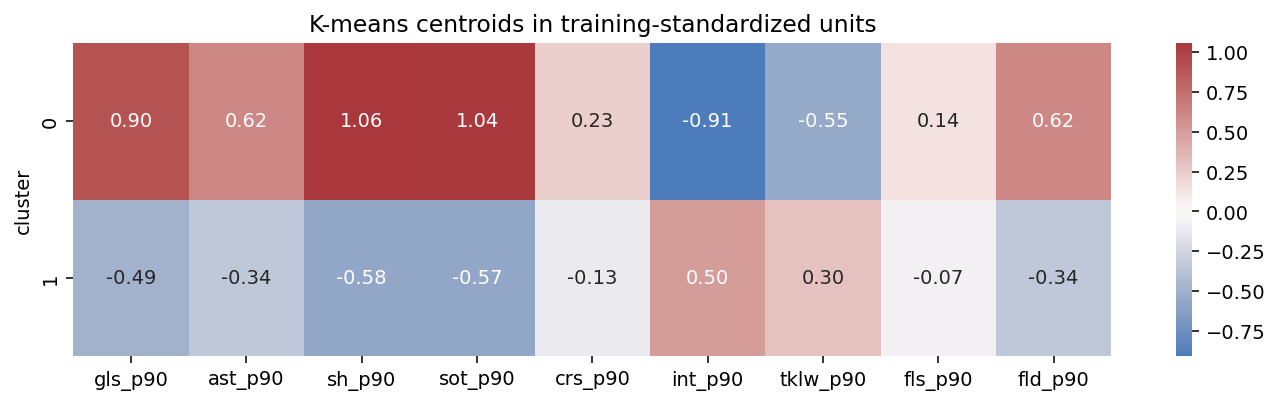

,,mean,min,max
position,method,,,
DF,euclidean_profile,1.0,1.000000,1.0
FW,euclidean_profile,0.8,0.666667,1.0
MF,euclidean_profile,1.0,1.000000,1.0


### attack_on_core

,k,training_silhouette,min_cluster_size,selection_scope
0,2,0.478624,233,training_only
1,3,0.391885,124,training_only
2,4,0.407588,62,training_only
3,5,0.333566,58,training_only
4,6,0.334661,21,training_only
5,7,0.321840,19,training_only
6,8,0.299510,14,training_only


,cluster,DF,FW,MF
0,0,306,28,228
1,1,5,163,65


,position_nmi,season_nmi,seed_ari_mean
0,0.329853,0.00022,0.996892


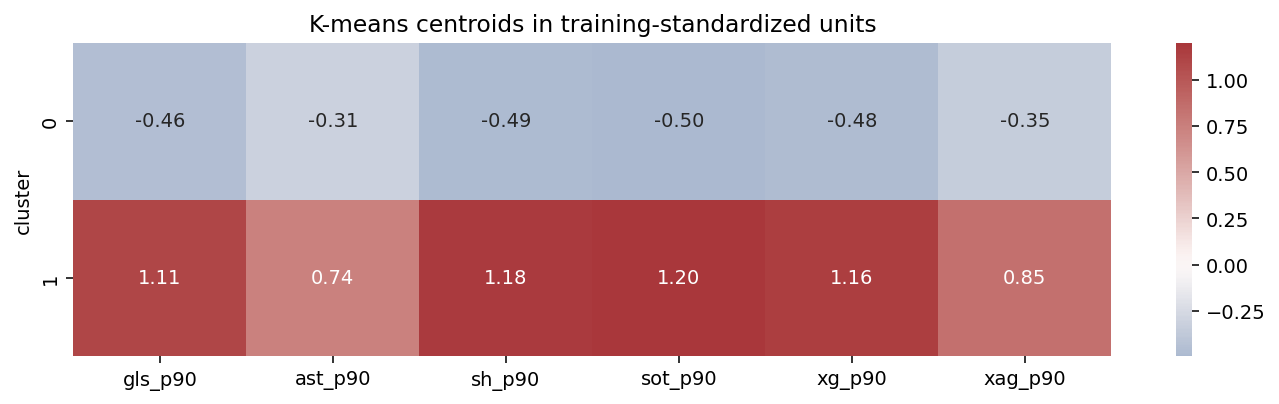

,,mean,min,max
position,method,,,
DF,euclidean_profile,0.916667,0.666667,1.0
FW,euclidean_profile,1.000000,1.000000,1.0
MF,euclidean_profile,1.000000,1.000000,1.0


In [6]:
for name,info in result['experiments'].items():
    display(Markdown('### '+name));display(pd.read_csv(ROOT/f'reports/experiments/collected_{name}_cluster_search.csv'))
    display(pd.read_csv(ROOT/f'reports/experiments/collected_{name}_cluster_positions.csv'))
    display(pd.DataFrame([info['cluster_analysis']]))
    display(Image(filename=str(ROOT/f'reports/experiments/collected_{name}_cluster_profiles.png')))
    robustness=pd.read_csv(ROOT/f'reports/experiments/collected_{name}_robustness.csv')
    display(robustness.groupby(['position','method']).top5_jaccard.agg(['mean','min','max']))


## Same-cohort feature ablation

The additional `attack_on_core` experiment uses the same development, validation, holdout players and seasons as the core experiment, but only six attacking features. This is a post-hoc diagnostic added after the initial trials, not independent confirmatory validation. The Euclidean comparison holds the retrieval method constant.

In [7]:
display(pd.read_csv(ROOT/'reports/experiments/collected_feature_ablation.csv'))

,phase,queries,method,mrr_core,mrr_attack,mrr_difference,difference_ci_low,difference_ci_high,design
0,holdout,249,euclidean_profile,0.223352,0.065909,0.157443,0.124631,0.192498,post_hoc_matched_cohort_diagnostic_not_indepen...
1,validation,248,euclidean_profile,0.227642,0.078611,0.149031,0.110485,0.186905,post_hoc_matched_cohort_diagnostic_not_indepen...


## Qualitative scouting alternatives

Reference players are reproducibly chosen as the highest-minute player in each position in the last development season. Lists require the same broad position, age ≤27, a single known club, another club and a different identity. They are historical descriptive alternatives; market-value budgets and actual-transfer success remain unevaluated. Broad DF/MF/FW labels lack detailed roles. Offensive-only defender similarity is especially limited by the missing defensive dimensions.

In [8]:
for name in ['offensive','core']:
    display(Markdown('### '+name))
    display(pd.read_csv(ROOT/f'reports/experiments/collected_{name}_shortlists.csv'))


### offensive

,reference,reference_entity,reference_club,position,season,rank,player,entity_id,team,age,...,method,similarity_score,budget_status,interpretation,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,Joselu,fbref:6265208f,Espanyol,FW,2022-2023,1,Enes Ünal,fbref:f8eca1b6,Getafe,25.0,...,euclidean_profile,-0.911714,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.424242,0.090909,2.484848,0.939394,0.354545,0.106061
1,Joselu,fbref:6265208f,Espanyol,FW,2022-2023,2,Valentín Castellanos,fbref:da76bab4,Girona,23.0,...,euclidean_profile,-0.918245,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.450520,0.000000,2.945707,1.108972,0.381209,0.058914
2,Joselu,fbref:6265208f,Espanyol,FW,2022-2023,3,Gorka Guruzeta,fbref:6b5ea2f4,Athletic Club,25.0,...,euclidean_profile,-1.043633,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.380014,0.063336,3.230120,1.076707,0.386348,0.063336
3,Joselu,fbref:6265208f,Espanyol,FW,2022-2023,4,Youssef En-Nesyri,fbref:04e17fd5,Sevilla,25.0,...,euclidean_profile,-1.052590,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.433474,0.054184,3.251054,1.246237,0.438892,0.059603
4,Joselu,fbref:6265208f,Espanyol,FW,2022-2023,5,El Bilal Touré,fbref:47c609d5,Almería,20.0,...,euclidean_profile,-1.089709,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.498418,0.142405,2.064873,0.996835,0.448576,0.092563
5,Sergi Darder,fbref:070a3904,Espanyol,MF,2022-2023,1,Marcos Llorente,fbref:02c15616,Atlético Madrid,27.0,...,euclidean_profile,-0.860542,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.052848,0.105696,1.268350,0.475631,0.110981,0.200822
6,Sergi Darder,fbref:070a3904,Espanyol,MF,2022-2023,2,Óliver Torres,fbref:58a9a4d9,Sevilla,27.0,...,euclidean_profile,-1.011407,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.126345,0.042115,0.926533,0.294806,0.109499,0.138980
7,Sergi Darder,fbref:070a3904,Espanyol,MF,2022-2023,3,Frenkie de Jong,fbref:1bacc518,Barcelona,25.0,...,euclidean_profile,-1.191252,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.071034,0.142068,0.639305,0.355170,0.085241,0.152723
8,Sergi Darder,fbref:070a3904,Espanyol,MF,2022-2023,4,Brian Ocampo,fbref:2e3995cd,Cádiz,23.0,...,euclidean_profile,-1.228663,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.080429,0.080429,1.045576,0.160858,0.040214,0.136729
9,Sergi Darder,fbref:070a3904,Espanyol,MF,2022-2023,5,Pedri,fbref:0d9b2d31,Barcelona,19.0,...,euclidean_profile,-1.273251,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.273279,0.045547,1.002024,0.409919,0.223178,0.227733


### core

,reference,reference_entity,reference_club,position,season,rank,player,entity_id,team,age,...,interpretation,gls_p90,ast_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
0,Joselu,fbref:6265208f,Alavés,FW,2021-2022,1,Dani Gómez,fbref:0e5ddc7c,Levante,23.0,...,descriptive alternatives; no transfer/relevanc...,0.338664,0.169332,2.624647,1.185325,0.423330,0.253998,0.338664,1.523989,1.693321
1,Joselu,fbref:6265208f,Alavés,FW,2021-2022,2,Raúl de Tomás,fbref:02ef8778,Espanyol,26.0,...,descriptive alternatives; no transfer/relevanc...,0.525051,0.092656,3.119423,1.235415,0.679478,0.185312,0.339739,1.080988,1.698696
2,Joselu,fbref:6265208f,Alavés,FW,2021-2022,3,Luis Javier Suárez,fbref:eeba07f8,Granada,23.0,...,descriptive alternatives; no transfer/relevanc...,0.253165,0.126582,2.689873,0.791139,1.202532,0.189873,0.443038,1.265823,1.139241
3,Joselu,fbref:6265208f,Alavés,FW,2021-2022,4,Iñaki Williams,fbref:6a99e0b1,Athletic Club,27.0,...,descriptive alternatives; no transfer/relevanc...,0.259273,0.162045,3.046453,1.134318,1.555636,0.097227,0.162045,0.777818,1.296363
4,Joselu,fbref:6265208f,Alavés,FW,2021-2022,5,Oihan Sancet,fbref:bdb624a3,Athletic Club,21.0,...,descriptive alternatives; no transfer/relevanc...,0.379747,0.253165,1.898734,0.886076,0.632911,0.316456,0.443038,1.265823,1.708861
5,Sergio Busquets,fbref:5ab0ea87,Barcelona,MF,2021-2022,1,Iñigo Ruiz de Galarreta,fbref:91f7631f,Mallorca,27.0,...,descriptive alternatives; no transfer/relevanc...,0.000000,0.000000,0.522496,0.195936,0.914369,1.306241,1.371553,1.632801,2.155298
6,Sergio Busquets,fbref:5ab0ea87,Barcelona,MF,2021-2022,2,Keidi Bare,fbref:03049c8c,Espanyol,23.0,...,descriptive alternatives; no transfer/relevanc...,0.060770,0.060770,0.243079,0.060770,0.425388,0.911546,1.033086,1.519244,1.762323
7,Sergio Busquets,fbref:5ab0ea87,Barcelona,MF,2021-2022,3,Óscar Valentín,fbref:592f3158,Rayo Vallecano,26.0,...,descriptive alternatives; no transfer/relevanc...,0.000000,0.000000,0.385364,0.035033,0.105099,1.366290,1.856754,1.751654,1.926820
8,Sergio Busquets,fbref:5ab0ea87,Barcelona,MF,2021-2022,4,Lucas Torró,fbref:0e4fef6e,Osasuna,27.0,...,descriptive alternatives; no transfer/relevanc...,0.033028,0.000000,1.122936,0.297248,0.231193,1.552294,1.321101,1.816514,1.585321
9,Sergio Busquets,fbref:5ab0ea87,Barcelona,MF,2021-2022,5,Iddrisu Baba,fbref:bfd381b3,Mallorca,25.0,...,descriptive alternatives; no transfer/relevanc...,0.046536,0.000000,1.070321,0.372285,0.232678,1.116856,1.396070,1.954498,1.768356


## Accepted matching method and source agreement

The proposed identity mapping is retained for exploration. Comparing source goals and xG is an audit of joins and provider coverage, not an identity accuracy test. Different exposure periods or provider definitions can explain disagreement. No Transfermarkt values or unreviewed cross-source fields enter the trained models. No cross-provider xG values are summed.

In [9]:
display(pd.read_csv(ROOT/'reports/experiments/collected_source_agreement.csv'))

,season,proposed_understat_club_links,comparable_rows,goals_exact_agreement,goals_absolute_difference_mean,xg_spearman,interpretation
0,2020-2021,410,410,406,0.009756,0.989944,Provisional join diagnostic; provider/exposure...
1,2021-2022,431,431,419,0.027842,0.985305,Provisional join diagnostic; provider/exposure...
2,2022-2023,406,405,403,0.004938,0.980823,Provisional join diagnostic; provider/exposure...
3,2023-2024,416,416,416,0.000000,0.981971,Provisional join diagnostic; provider/exposure...
4,2024-2025,405,405,404,0.002469,0.984636,Provisional join diagnostic; provider/exposure...
5,2025-2026,249,249,249,0.000000,0.918728,Provisional join diagnostic; provider/exposure...


## MLflow and reproducibility

Collected-data runs use their own experiment, distinct from the legacy and synthetic demonstrations. Runs record owner/project/dataset/environment tags, dataset version, code hashes, Git commit, parameters, comparison metrics, model files and evaluation figures. The portable exports are downloaded from genuinely logged MLflow artifacts. The existing Streamlit model remains unchanged pending a separate application integration step.

In [10]:
for name,info in result['experiments'].items():
    record=json.loads((ROOT/f'reports/mlflow_export/collected_{name}_run.json').read_text())
    assert record['status']=='FINISHED' and record['run_id']==info['mlflow_run_id']
    display(pd.DataFrame([{'cohort':name,'run_id':record['run_id'],'status':record['status'],'dataset_version':record['tags']['dataset'],'model':info['model_path']}]))
display(Markdown('Remaining limits: '+ '; '.join(result['limitations'])))


,cohort,run_id,status,dataset_version,model
0,offensive,c9e47c4ca7984652b79dd95131063041,FINISHED,28dc55e8885f1db9cef608567ca2626231f3bab94d1bb3...,models/real/collected_offensive_recommender.jo...


,cohort,run_id,status,dataset_version,model
0,core,28aca2ec30514eafa181b7945f2c6dcd,FINISHED,28dc55e8885f1db9cef608567ca2626231f3bab94d1bb3...,models/real/collected_core_recommender.joblib


,cohort,run_id,status,dataset_version,model
0,attack_on_core,54262e95cd684023bed779bced078bb2,FINISHED,28dc55e8885f1db9cef608567ca2626231f3bab94d1bb3...,models/real/collected_attack_on_core_recommend...


Remaining limits: Retrieval does not measure transfer success, future performance prediction or club-fit relevance; Future candidate profiles are evaluation targets; they cannot be known at scouting time; Returning 450+ minute outfield players create selection/survivorship bias; Unknown archive publication dates prevent strict historical as-of claims; Segunda, goalkeeper, budget and genuine transfer validation remain unavailable; Cross-source identity method accepted; individual links still unverified